# Module 2 · Logistic Regression
Dự báo nhóm PM2.5 tại t+1 giờ từ lịch sử đến t. Phân vị train, không phải AQI chính thức. Notebook dùng cùng pipeline với API và Streamlit.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from module2 import *
RUN_TRAINING = False
if RUN_TRAINING:
    from train import main
    main()

## Dữ liệu và chống rò rỉ
12 trạm, giờ Bắc Kinh. Mục tiêu là số đo thực t+1, không điền thiếu. Lag theo từng trạm và giờ thực. Train trước 2015-03-01; validation trước 2016-03-01; test trước 2017-03-01. Chia theo target_time.

{'raw_rows': 420768,
 'exact_duplicates_removed': 0,
 'rows_on_hourly_grid': 420768,
 'inserted_hours': 0,
 'stations': ['Aotizhongxin',
  'Changping',
  'Dingling',
  'Dongsi',
  'Guanyuan',
  'Gucheng',
  'Huairou',
  'Nongzhanguan',
  'Shunyi',
  'Tiantan',
  'Wanliu',
  'Wanshouxigong'],
 'start': '2013-03-01 00:00:00',
 'end': '2017-02-28 23:00:00',
 'invalid_values': {'PM2.5': 0,
  'PM10': 0,
  'SO2': 0,
  'NO2': 0,
  'CO': 0,
  'O3': 0,
  'TEMP': 0,
  'PRES': 0,
  'DEWP': 0,
  'RAIN': 0,
  'WSPM': 0},
 'source': 'https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data',
 'attribution': 'Chen, S. (2017), DOI 10.24432/C5RK5G, CC BY 4.0',
 'provenance': 'Existing shared CSVs; original download time unknown.',
 'timezone': 'Asia/Shanghai'}

,station,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
0,Aotizhongxin,925,718,935,1023,1776,1719,20,20,20,20,14,81
1,Changping,774,582,628,667,1521,604,53,50,53,51,43,140
2,Dingling,779,656,730,1234,2012,1214,53,50,53,51,43,140
3,Dongsi,750,553,663,1601,3197,664,20,20,20,20,14,78
4,Guanyuan,616,429,474,659,1753,1173,20,20,20,20,14,81
5,Gucheng,646,381,507,668,1401,729,51,50,51,43,42,159
6,Huairou,953,777,980,1639,1422,1151,51,53,53,55,49,302
7,Nongzhanguan,628,440,446,692,1206,506,20,20,20,20,14,78
8,Shunyi,913,548,1296,1365,2178,1489,51,51,54,51,44,483
9,Tiantan,677,597,1118,744,1126,843,20,20,20,20,14,78


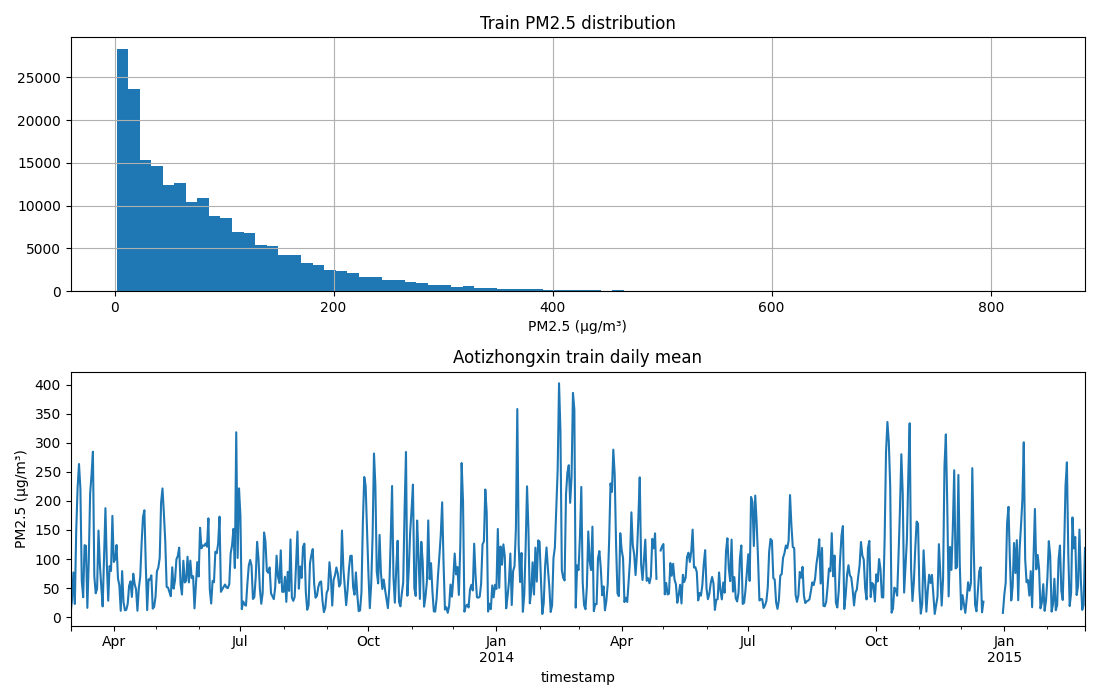

In [2]:
audit=json.loads((REPORTS/'data_audit.json').read_text(encoding='utf-8'))
display({k:v for k,v in audit.items() if k != 'sha256'})
display(pd.read_csv(REPORTS/'missing_by_station.csv'))
display(Image(filename=str(REPORTS/'eda.png')))

## Quy tắc nhãn và số mẫu
q1, q2 tính từ mục tiêu train gộp 12 trạm. q1 thuộc Thấp, q2 thuộc Trung bình. Ngưỡng cố định cho validation/test.

In [3]:
display(json.loads((ARTIFACTS/'label_policy.json').read_text(encoding='utf-8')))
display(pd.read_csv(REPORTS/'split_support.csv').groupby(['split','label'])['count'].sum().unstack())

{'strategy': 'train_quantiles_v1',
 'thresholds': [34.0, 96.0],
 'classes': ['Thấp', 'Trung bình', 'Cao'],
 'boundaries': ['0 <= p <= q1', 'q1 < p <= q2', 'p > q2'],
 'unit': 'µg/m³',
 'fit_target_time': ['2013-03-01', '2015-03-01 (exclusive)'],
 'official_aqi': False}

label,0,1,2
split,,,
test,38996,34983,28774
train,69001,68706,68270
validation,42945,33971,26371


## Mô hình và thực nghiệm
$P(y=k|x)=\exp(w_k^Tx+b_k)/\sum_j\exp(w_j^Tx+b_j)$. C là nghịch mức điều chuẩn L2. Imputer, scaler, one-hot chỉ fit train. Chọn đặc trưng và tham số bằng Macro-F1 validation.

In [4]:
display(pd.read_csv(REPORTS/'experiments.csv'))
display(pd.read_csv(REPORTS/'metrics.csv'))

,feature_set,C,class_weight,fit_seconds,warnings,converged,n,accuracy,macro_f1,recall_high,high_to_low
0,basic,1.00,NaN,2.634690,[],True,103287,0.894943,0.893425,0.889879,0.001706
1,lag,1.00,NaN,3.552772,[],True,103287,0.897064,0.895755,0.893937,0.002351
2,rolling,1.00,NaN,22.585153,[],True,103287,0.899203,0.898219,0.897311,0.001555
3,rolling,0.01,NaN,13.012927,[],True,103287,0.898283,0.897255,0.895453,0.001555
4,rolling,0.01,balanced,8.581841,[],True,103287,0.898371,0.897362,0.896212,0.001555
5,rolling,0.10,NaN,8.296541,[],True,103287,0.899194,0.898195,0.897160,0.001441
6,rolling,0.10,balanced,6.603959,[],True,103287,0.899339,0.898325,0.897349,0.001441
7,rolling,1.00,balanced,8.292701,[],True,103287,0.899339,0.898368,0.897804,0.001555
8,rolling,10.00,NaN,8.988984,[],True,103287,0.899358,0.898355,0.897425,0.001593
9,rolling,10.00,balanced,8.230294,[],True,103287,0.899658,0.898651,0.897804,0.001517


,split,model,scope,fallback_rate,n,accuracy,macro_f1,recall_high,high_to_low
0,validation,majority,all,0.007823,103287,0.415783,0.195785,0.000000,1.000000
1,validation,majority,observed_current,0.007823,102479,0.414553,0.195375,0.000000,1.000000
2,validation,persistence,all,0.007823,103287,0.896870,0.895636,0.911797,0.005650
3,validation,persistence,observed_current,0.007823,102479,0.899433,0.898272,0.916140,0.000914
4,validation,logistic,all,0.007823,103287,0.899658,0.898651,0.897804,0.001517
5,validation,logistic,observed_current,0.007823,102479,0.900877,0.899986,0.899337,0.001334
6,test,majority,all,0.008924,102753,0.379512,0.183404,0.000000,1.000000
7,test,majority,observed_current,0.008924,101836,0.379414,0.183370,0.000000,1.000000
8,test,persistence,all,0.008924,102753,0.895088,0.894916,0.906930,0.009974
9,test,persistence,observed_current,0.008924,101836,0.899633,0.899469,0.914238,0.001997


## Đánh giá và phân tích lỗi
Majority lấy lớp phổ biến nhất train. Persistence lấy lớp của PM2.5(t), khi thiếu dùng majority. So sánh trên cùng tập mẫu.

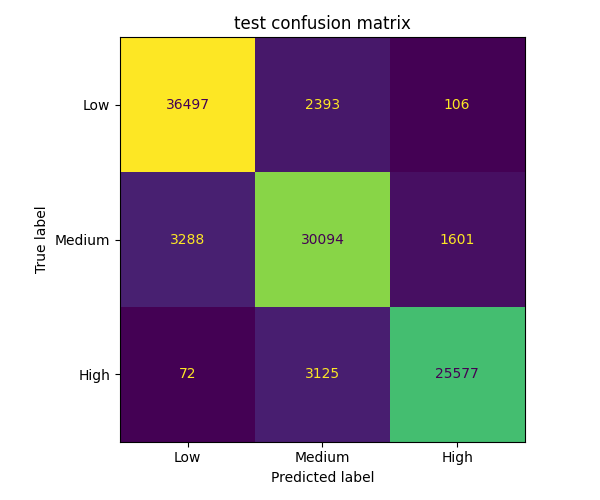

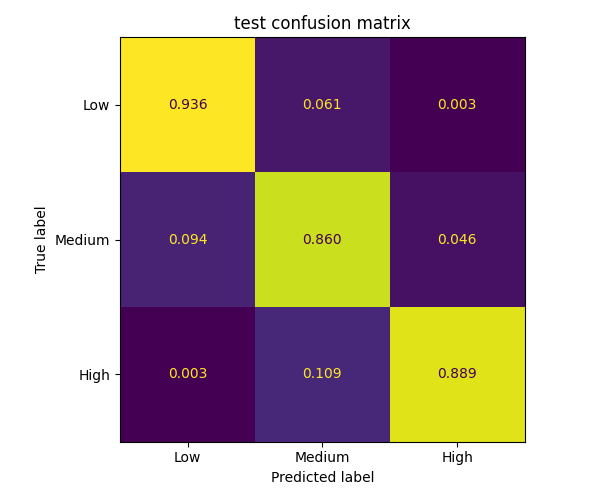

,precision,recall,f1-score,support
Thấp,0.915699,0.935917,0.925697,38996.000000
Trung bình,0.845052,0.860246,0.852582,34983.000000
Cao,0.937436,0.888893,0.912519,28774.000000
accuracy,0.896986,0.896986,0.896986,0.896986
macro avg,0.899396,0.895019,0.896933,102753.000000
weighted avg,0.897734,0.896986,0.897114,102753.000000


{'majority': {'n': 10221,
  'accuracy': 0.2727717444477057,
  'macro_f1': 0.14287544520460194,
  'recall_high': 0.0,
  'high_to_low': 1.0},
 'persistence': {'n': 10221,
  'accuracy': 0.0,
  'macro_f1': 0.0,
  'recall_high': 0.0,
  'high_to_low': 0.023284313725490197},
 'logistic': {'n': 10221,
  'accuracy': 0.27198904216808534,
  'macro_f1': 0.25343562263005454,
  'recall_high': 0.12295751633986927,
  'high_to_low': 0.02369281045751634}}

,dimension,value,n,accuracy,macro_f1,recall_high,high_to_low
0,station,Aotizhongxin,8581,0.896166,0.896258,0.879484,0.002418
1,station,Changping,8646,0.894865,0.892554,0.897059,0.001521
2,station,Dingling,8477,0.901498,0.895862,0.887226,0.005345
3,station,Dongsi,8381,0.898103,0.898518,0.901372,0.003337
4,station,Guanyuan,8570,0.893816,0.894200,0.878515,0.001875
5,station,Gucheng,8605,0.888205,0.889519,0.868199,0.002682
6,station,Huairou,8622,0.904199,0.900996,0.883083,0.001552
7,station,Nongzhanguan,8618,0.899049,0.899584,0.896645,0.001543
8,station,Shunyi,8434,0.903486,0.903208,0.900377,0.002930
9,station,Tiantan,8622,0.895848,0.897233,0.898760,0.001200


In [5]:
display(Image(filename=str(REPORTS/'confusion_test_count.png')))
display(Image(filename=str(REPORTS/'confusion_test_true.png')))
report=json.loads((REPORTS/'classification_report.json').read_text(encoding='utf-8'))
display(pd.DataFrame(report['test']).T)
display(report['transition_metrics'])
display(pd.read_csv(REPORTS/'test_slices.csv'))

## Hệ số
Numeric đã chuẩn hóa; one-hot không cùng thang đo. Các lag có tương quan; hệ số không thể hiện quan hệ nhân quả.

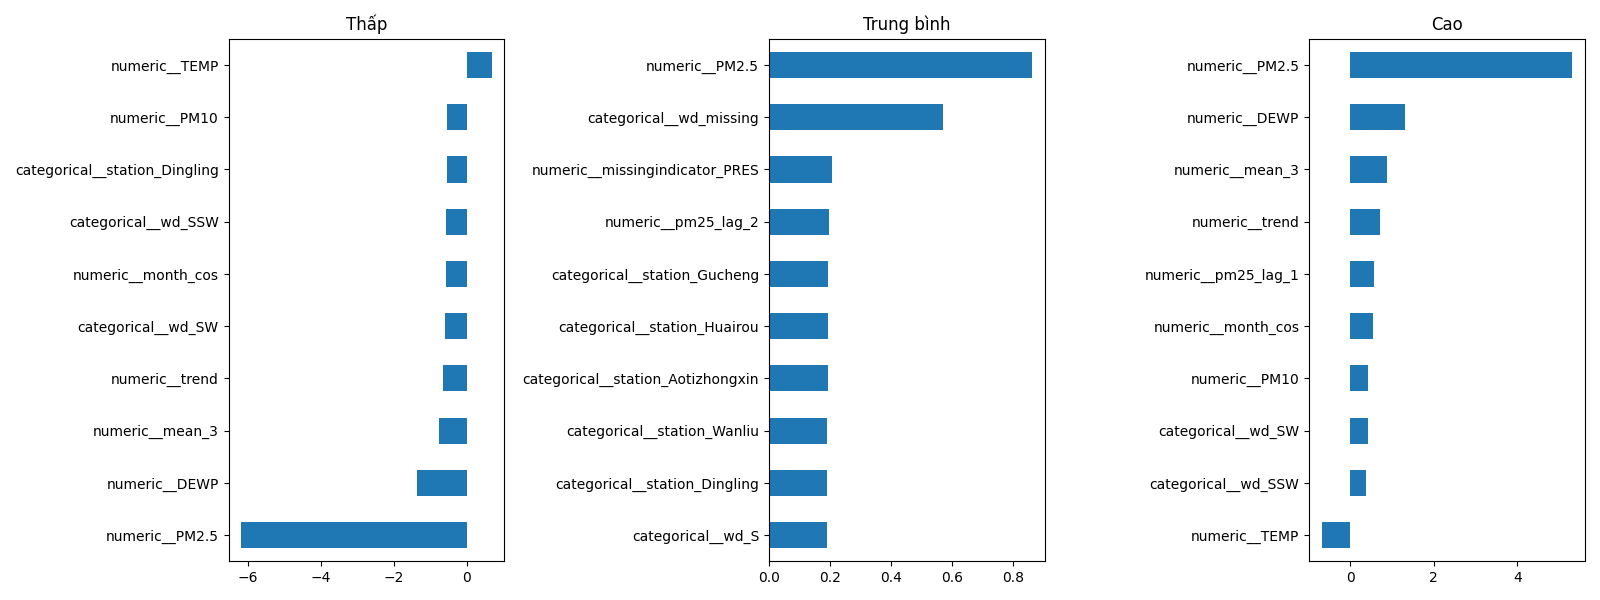

,Unnamed: 0,Thấp,Trung bình,Cao
0,numeric__PM2.5,-6.181724,0.861896,5.319828
1,numeric__PM10,-0.533698,0.097753,0.435945
2,numeric__SO2,-0.229654,0.042752,0.186903
3,numeric__NO2,-0.301927,0.048100,0.253826
4,numeric__CO,-0.255761,0.132770,0.122990
5,numeric__O3,-0.170190,0.031005,0.139184
6,numeric__TEMP,0.678576,0.001131,-0.679706
7,numeric__PRES,-0.038178,0.038872,-0.000695
8,numeric__DEWP,-1.357887,0.049964,1.307923
9,numeric__RAIN,0.165901,-0.000653,-0.165248


In [6]:
display(Image(filename=str(REPORTS/'coefficients.png')))
display(pd.read_csv(REPORTS/'coefficients.csv').head(20))

## Dự đoán bằng API dùng chung với app

In [7]:
history, _, _ = load_data()
features = build_features(history, 'Aotizhongxin', '2016-05-01 09:00')
result = predict_pollution_class(features)
assert abs(sum(result['probabilities'].values())-1)<1e-10
display(result)

{'station': 'Aotizhongxin',
 'as_of_time': '2016-05-01T09:00:00+08:00',
 'target_time': '2016-05-01T10:00:00+08:00',
 'predicted_class': 'Cao',
 'probabilities': {'Thấp': 3.815909521717416e-12,
  'Trung bình': 0.0006170750787729136,
  'Cao': 0.9993829249174111},
 'label_policy': 'train_quantiles_v1',
 'model_version': 'module2_v1',
 'missing_feature_count': 0}

## Kết luận và giới hạn

In [8]:
display(Markdown((REPORTS/'REPORT.md').read_text(encoding='utf-8')))

# Báo cáo Module 2 Logistic Regression

Dự báo nhóm nồng độ PM2.5 tại t+1 giờ, dùng số đo đã có đến t. Đây là dự báo cuốn chiếu; không phải AQI chính thức hoặc khuyến cáo sức khỏe.

Dữ liệu: 420,768 dòng, 12 trạm. Số mẫu train/validation/test: 205,977 / 103,287 / 102,753.
Ngưỡng train: q1=34, q2=96 µg/m³. Thấp: p≤q1; Trung bình: q1<p≤q2; Cao: p>q2.
Cấu hình chọn bằng validation: rolling, C=10.0, class_weight=balanced. Không refit train+validation.

| Mô hình | Accuracy | Macro-F1 | Recall Cao | Cao → Thấp |
|---|---:|---:|---:|---:|
| majority | 0.3795 | 0.1834 | 0.0000 | 1.0000 |
| persistence | 0.8951 | 0.8949 | 0.9069 | 0.0100 |
| logistic | 0.8970 | 0.8969 | 0.8889 | 0.0025 |

Chênh lệch Macro-F1 Logistic so với persistence: +0.0020. Persistence mạnh vì nồng độ thường ổn định giữa hai giờ liền nhau.
Tỷ lệ fallback persistence trên test: 0.89%. So sánh trên cùng tập con có PM2.5(t) nằm trong metrics.csv.
Có 10,221 giờ chuyển lớp khi PM2.5(t) quan sát được; Macro-F1 Logistic tại các giờ này: 0.2534.

## Phương pháp và diễn giải
Logistic Regression đa lớp dùng softmax P(y=k|x)=exp(w_k·x+b_k)/Σ_j exp(w_j·x+b_j). C nhỏ tăng điều chuẩn L2. Numeric được điền median và chuẩn hóa chỉ từ train; station và wd dùng one-hot. Macro-F1 là trung bình F1 của ba lớp, kể cả khi một lát cắt thiếu lớp.
Lag theo từng trạm trên lưới giờ; không nội suy mục tiêu. Chia theo target_time để nhãn train không tràn sang validation. Thử ba bộ đặc trưng ở C=1 rồi tối đa tám cấu hình C/weight trên bộ được chọn; chỉ đánh giá test sau khi khóa cấu hình.
Hệ số dương làm tăng logit của lớp tương ứng khi giữ các biến khác cố định. Hệ số numeric gắn với một độ lệch chuẩn; không so trực tiếp với one-hot và không suy diễn nhân quả. PM2.5 và các lag tương quan nên hệ số có thể khó diễn giải.

## Hạn chế
Nhãn phân vị là mức tương đối tại Bắc Kinh, không phải mức an toàn sức khỏe. Mẫu thiếu mục tiêu bị loại có thể gây thiên lệch. Xác suất chưa được hiệu chỉnh. Chưa đánh giá trạm mới, Việt Nam hoặc dữ liệu thời gian thực. Mô hình tuyến tính có thể bỏ lỡ biến động đột ngột.
Nguồn: Chen, S. (2017), UCI Beijing Multi-Site Air Quality, DOI 10.24432/C5RK5G, CC BY 4.0. CSV được cung cấp sẵn; không xác định được thời điểm tải gốc. SHA-256 được lưu trong data_audit.json.

## Tệp kết quả
experiments.csv: toàn bộ lượt huấn luyện và cảnh báo; classification_report.json: precision/recall/F1/support; test_slices.csv: trạm/tháng/giờ và support; test_predictions.csv: nhãn, baseline và xác suất từng mẫu; coefficients.csv: hệ số theo lớp.

## Phân tích bổ sung

Recall Cao của Logistic là 88,89%, thấp hơn persistence 90,69%, dù Macro-F1 cao hơn. Lỗi Cao → Thấp giảm từ khoảng 1,00% xuống 0,25%; cần cân nhắc cả hai khi trình bày kết quả.

Theo các lát cắt test, Gucheng có Macro-F1 thấp nhất trong các trạm (0,8895; 8.605 mẫu). Tháng 6 thấp nhất trong các tháng (0,8524; 8.433 mẫu); giờ 9 thấp nhất trong các giờ (0,8828; 4.302 mẫu). Đây là phân tích sau đánh giá, không dùng để chọn lại mô hình.
